Now that we have a whole lot of spectra created, we should have an easy way to visualise all of them by saving them in a more accessible file type. Let's just read in these files using dstools and then save them as png files which we can bring back to the local machine.

Note a large chunk of this code is commented out to avoid massive file sizes

In [31]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum, LightCurve
from dstools.plotting import plot_ds, plot_lightcurve
import os
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle

In [33]:
vis_path = Path('../visibility_files/')
ds_files = list(vis_path.rglob('*.ds'))

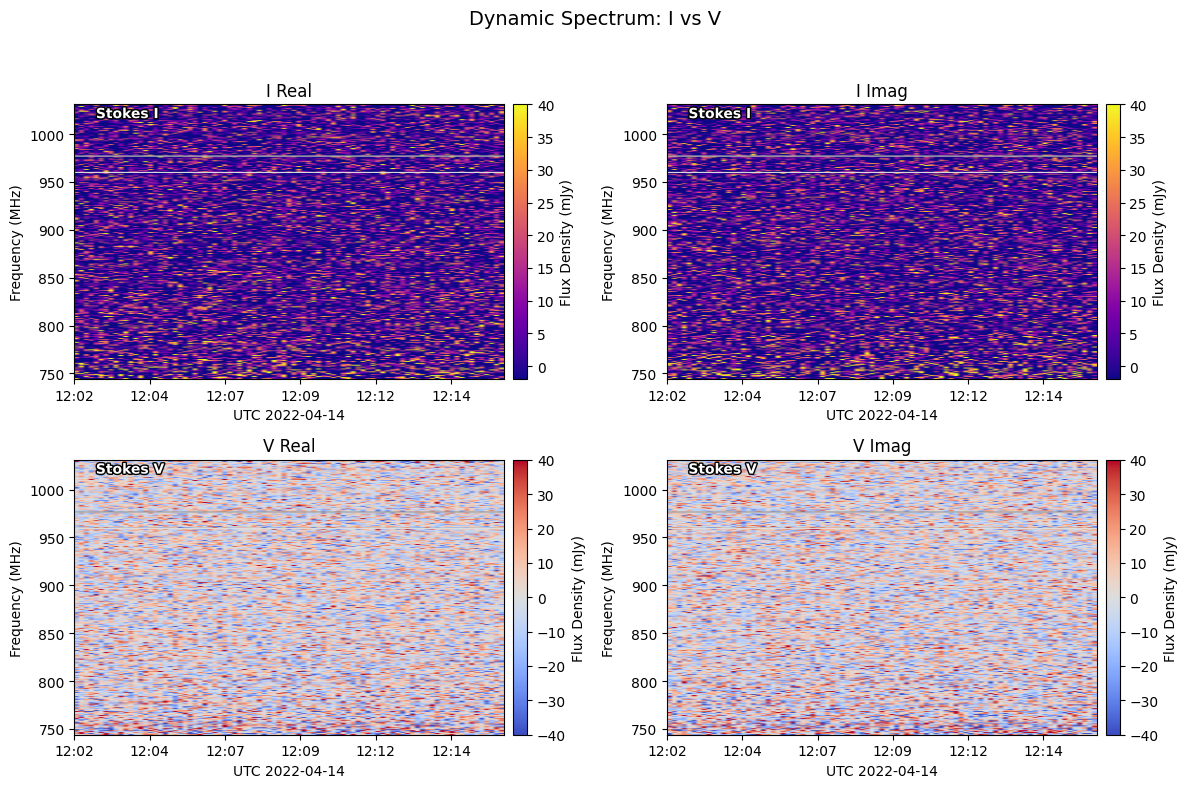

In [4]:
ds = DynamicSpectrum(ds_path=ds_files[4])
cmax_val = 40

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 0])
axes[0, 0].set_title('I Real')

plot_ds(ds, stokes='I', cmax=cmax_val, imag=True, fig=fig, ax=axes[0, 1])
axes[0, 1].set_title('I Imag')

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 0])
axes[1, 0].set_title('V Real')

plot_ds(ds, stokes='V', cmax=cmax_val, imag=True, fig=fig, ax=axes[1, 1])
axes[1, 1].set_title('V Imag')

fig.suptitle('Dynamic Spectrum: I vs V', fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Now we know it works as intended, we can save all of our figures somewhere easy to retrieve.

In [4]:
for ds_file in ds_files:

    # For the plot title and the file name when saved
    name = ds_file.stem

    # Read in the DS
    ds = DynamicSpectrum(ds_path=ds_file)

    # Create a diagnostic plot
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    plot_ds(ds, stokes='I', cmax=50, imag=False, fig=fig, ax=axes[0, 0])
    axes[0, 0].set_title('I Real')
    
    plot_ds(ds, stokes='I', cmax=50, imag=True, fig=fig, ax=axes[0, 1])
    axes[0, 1].set_title('I Imag')
    
    plot_ds(ds, stokes='V', cmax=50, imag=False, fig=fig, ax=axes[1, 0])
    axes[1, 0].set_title('V Real')
    
    plot_ds(ds, stokes='V', cmax=50, imag=True, fig=fig, ax=axes[1, 1])
    axes[1, 1].set_title('V Imag')
    
    fig.suptitle(name)
    plt.tight_layout()
    plt.savefig(f'../rsync_folder/ds_images/{name}.png')
    plt.close(fig)

# Messing around with individual DS

If there are sources where we expect some sort of behaviour, we can just plot them here with additional constraints/averaging to see what pops out.

In [23]:
matches = [p for p in ds_files if "hd_104919_55363" in str(p)]

In [24]:
matches

[PosixPath('../visibility_files/hd_104919/55363/hd_104919_55363.ds')]

In [18]:
matches[0].stem

'hd_104919_22345'

In [19]:
len(matches)

57

In [70]:
# tavg=1
# favg=5
# cmax_val = 50

# for i in range(0, len(matches)):

#     ds = DynamicSpectrum(ds_path=matches[i],tavg=tavg, favg=favg)
#     lc = LightCurve(ds)

#     fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
#     plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 0])
#     axes[0, 0].set_title('I Real')
    
#     plot_ds(ds, stokes='I', cmax=cmax_val, imag=True, fig=fig, ax=axes[0, 1])
#     axes[0, 1].set_title('I Imag')
    
#     plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 0])
#     axes[1, 0].set_title('V Real')
    
#     plot_ds(ds, stokes='V', cmax=cmax_val, imag=True, fig=fig, ax=axes[1, 1])
#     axes[1, 1].set_title('V Imag')
    
#     fig.suptitle(f'{str(matches[i].stem)}', fontsize=14)
    
#     plt.tight_layout(rect=[0, 0, 1, 0.95])
#     plt.show()
#     plt.close()

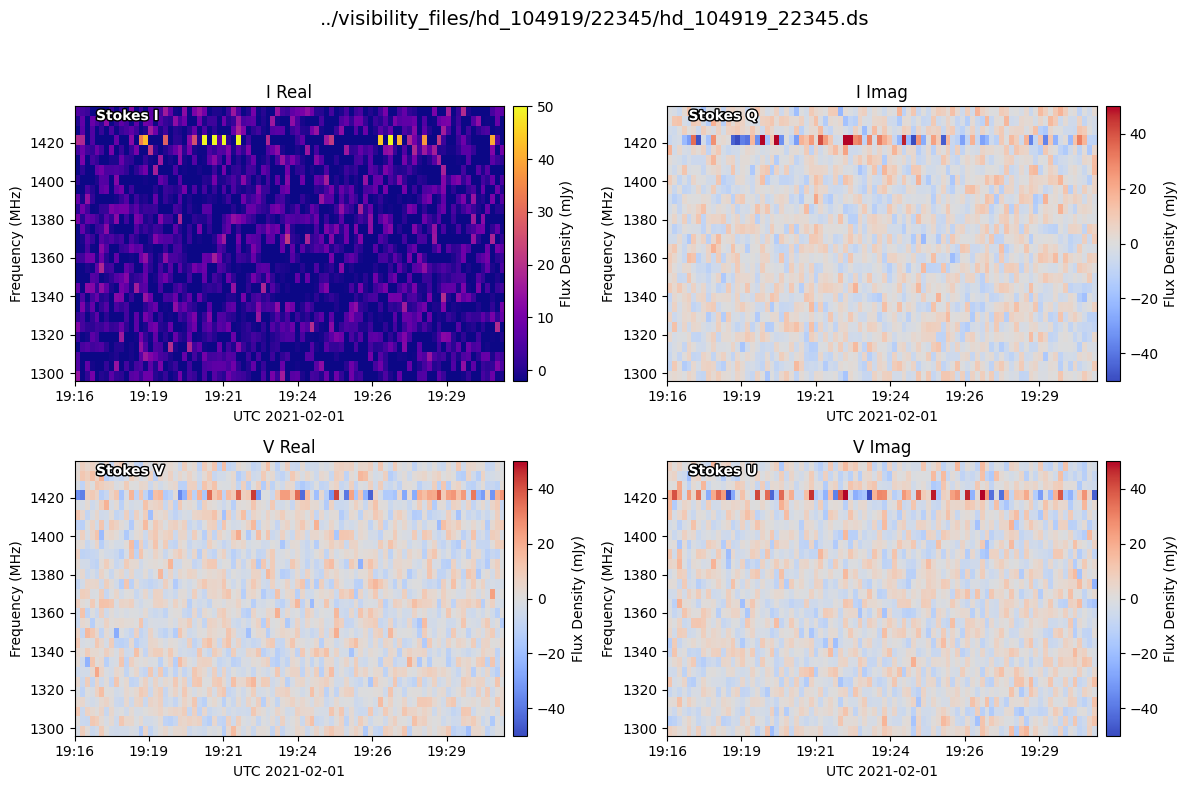

In [10]:
tavg=1
favg=5
ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=favg)
lc = LightCurve(ds)
cmax_val = 50

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 0])
axes[0, 0].set_title('I Real')

plot_ds(ds, stokes='Q', cmax=cmax_val, imag=False, fig=fig, ax=axes[0, 1])
axes[0, 1].set_title('I Imag')

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 0])
axes[1, 0].set_title('V Real')

plot_ds(ds, stokes='U', cmax=cmax_val, imag=False, fig=fig, ax=axes[1, 1])
axes[1, 1].set_title('V Imag')

fig.suptitle(f'{str(matches[0])}', fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

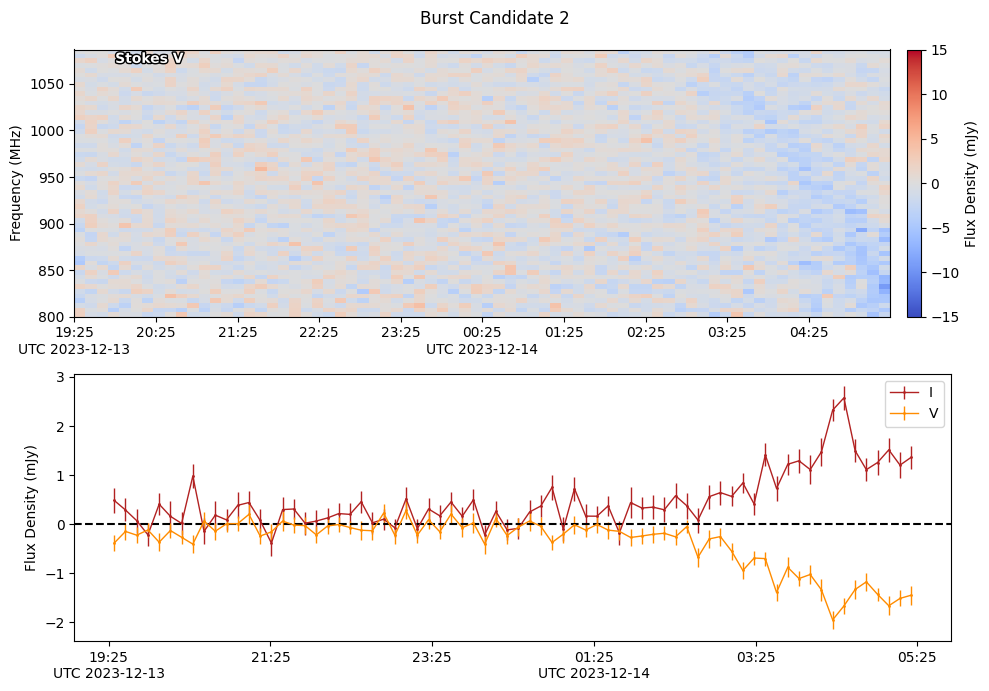

In [28]:
tavg=50
favg=5
ds = DynamicSpectrum(ds_path=matches[0],tavg=tavg, favg=favg)
lc = LightCurve(ds)
cmax_val = 15

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# Dynamic spectrum
plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])

# # Dynamic spectrum
# plot_ds(ds, stokes='V', cmax=cmax_val, imag=True, fig=fig, ax=ax[1])

# # Dynamic spectrum
# plot_ds(ds, stokes='I', cmax=10, imag=False, fig=fig, ax=ax[1])

# Lightcurve
plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[1])
ax[1].axhline(0, c = 'black', ls = '--')

# plt.suptitle(f'{ds_file.stem}')
plt.suptitle('Burst Candidate 2')
plt.tight_layout()
plt.show()

In [ ]:
# Saving plots for HD 104919

In [68]:
# make sure to manually overwrite these to 50,5,10 for matches[0] --> EMU
tavg = 5
favg = 5
cmax_val = 50

for match in matches:
    
    name = match.stem
    ds = DynamicSpectrum(ds_path=match, tavg=tavg, favg=favg)
    lc = LightCurve(ds)
    
    fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex = True)
    
    # Dynamic spectrum
    plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])
    
    # Dynamic spectrum
    plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[1])
    
    # Lightcurve
    plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[2])
    ax[2].axhline(0, c = 'black', ls = '--')
    
    plt.suptitle(name)
    plt.tight_layout()
    plt.savefig(f'../rsync_folder/hd_104919_plots/{name}.png')
    plt.close(fig)

In [69]:
# run this one to make the EMU plot
tavg = 50
favg = 5
cmax_val = 10

match = matches[0]
    
name = match.stem
ds = DynamicSpectrum(ds_path=match, tavg=tavg, favg=favg)
lc = LightCurve(ds)

fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex = True)

# Dynamic spectrum
plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])

# Dynamic spectrum
plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[1])

# Lightcurve
plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[2])
ax[2].axhline(0, c = 'black', ls = '--')

plt.suptitle(name)
plt.tight_layout()
plt.savefig(f'../rsync_folder/hd_104919_plots/{name}.png')
plt.close(fig)

In [145]:
tavg=5
favg=5
ds = DynamicSpectrum(ds_path=matches[1],tavg=tavg, favg=favg)
lc = LightCurve(ds)
print('Fractional circular polarisation:') # Which one is correct?
print(np.real(np.nanmean(ds.data['V']) / np.nanmean(ds.data['I'])))
print(np.real(np.nanmean(ds.data['V'] / ds.data['I'])))

Fractional circular polarisation:
-0.03684436319172979
0.005496020253557934


# Making diagnostic plots for HD 104919

I want to include the cutouts, the dynamic spectra, and the lightcurve for each of the observations, to do that, we have to add in our cutouts.

In [46]:
cutouts = ['../cutouts/hd_104919_image.v.EMU_1223-64.SB55363.cont.taylor.0.restored.conv.fits',
           '../cutouts/hd_104919_image.v.RACS_1223-64.SB36479.cont.taylor.0.restored.conv.fits',
           '../cutouts/hd_104919_image.v.VAST_1224-62.SB62277.cont.taylor.0.restored.conv.fits',
           '../cutouts/hd_104919_image.v.VAST_1135-62.SB62276.cont.taylor.0.restored.conv.fits']

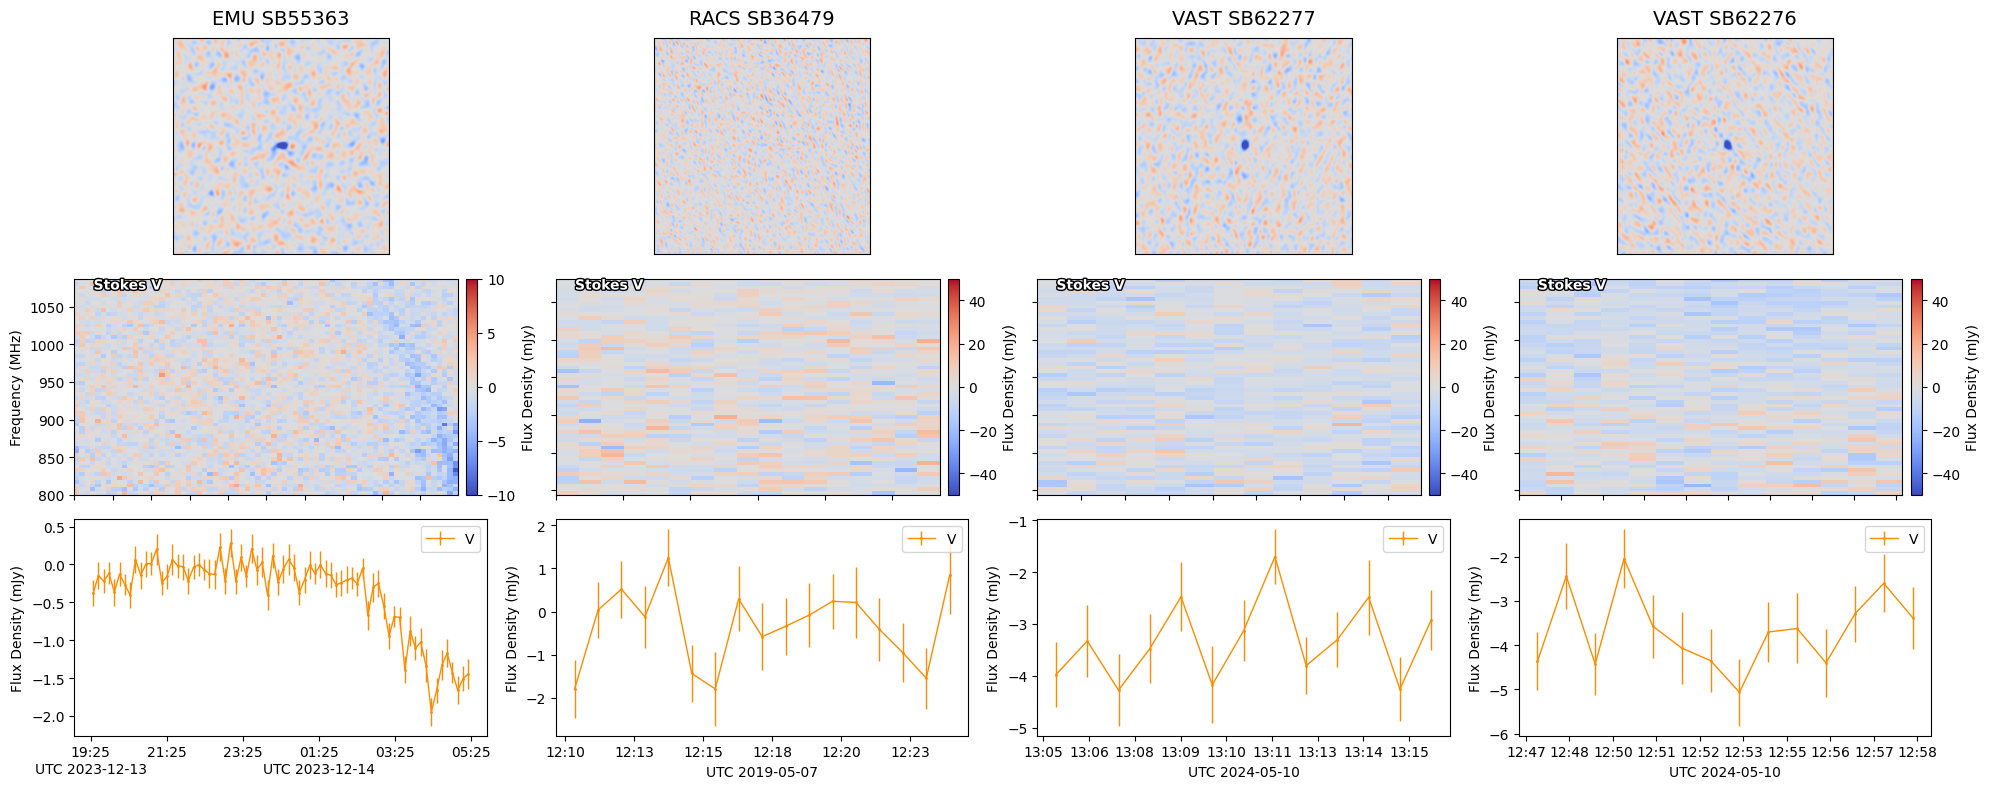

In [96]:
fs = [5,5,5,5]
ts = [50,5,5,5]
cmaxes = [10,50,50,50]

titles = ["EMU SB55363", "RACS SB36479", "VAST SB62277", "VAST SB62276"]

fig, ax = plt.subplots(3, 4, figsize=(20, 8))

for i, (cutout, ds_file) in enumerate(zip(cutouts, matches)):

    # -------------------------
    # Get data
    # -------------------------
    ds = DynamicSpectrum(ds_path=ds_file, tavg=ts[i], favg=fs[i])
    lc = LightCurve(ds)

    # -------------------------
    # Row 1: Cutout image
    # -------------------------
    with fits.open(cutout) as hdul:
        data = np.squeeze(hdul[0].data)

    rect_size = 20
    ny, nx = data.shape
    mask = np.ones_like(data, dtype=bool)
    mask[ny//2-rect_size:ny//2+rect_size,
         nx//2-rect_size:nx//2+rect_size] = False

    noise = np.nanstd(data[mask])

    ax[0, i].imshow(
        data,
        origin="lower",
        cmap="coolwarm",
        vmin=-7*noise,
        vmax=7*noise
    )

    # remove ticks / labels from cutouts
    ax[0, i].set_xticks([])
    ax[0, i].set_yticks([])

    # column title
    ax[0, i].set_title(titles[i], fontsize=14, pad=10)

    # -------------------------
    # Row 2: Dynamic spectrum
    # -------------------------
    plot_ds(
        ds,
        stokes='V',
        cmax=cmaxes[i],
        imag=False,
        fig=fig,
        ax=ax[1, i]
    )

    # remove x labels/ticks for all DS panels
    ax[1, i].set_xlabel("")
    ax[1, i].set_xticklabels([])

    # only keep leftmost y label
    if i != 0:
        ax[1, i].set_ylabel("")
        ax[1, i].set_yticklabels([])

    # -------------------------
    # Row 3: Light curve
    # -------------------------
    plot_lightcurve(
        lc,
        stokes='V',
        fig=fig,
        ax=ax[2, i]
    )

plt.tight_layout()
plt.show()

# Making similar diagnostics for the rest of our DS

So we know we can get things appearing when we look at our lightcurves and averaged DS, so lets try this on the rest of our data to see if anything was hiding from us initially.

First, lets get rid of the HD 104919 files since we don't need duplicates.

In [4]:
ds_files_filtered = [p for p in ds_files if "hd_104919" in str(p)]

In [140]:
for ds in ds_files_filtered:

    temp_ds = DynamicSpectrum(ds_path=ds) # To get data for averaging
    duration = temp_ds.tmax
    
    if duration > 4: 
        tavg = 50
        cmax_val = 10
    elif duration > 0.75:
        tavg=20
        cmax_val = 10
    else:
        tavg=5
        cmax_val = 30
        
    favg = 5
    
    name = ds.stem
    ds = DynamicSpectrum(ds_path=ds, tavg=tavg, favg=favg)
    lc = LightCurve(ds)
    
    fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex = True)
    
    # Dynamic spectrum
    plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])
    
    # Dynamic spectrum
    plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[1])
    
    # Lightcurve
    plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[2])
    ax[2].axhline(0, c = 'black', ls = '--')
    
    plt.suptitle(f'{name}')
    plt.tight_layout()
    plt.savefig(f'../rsync_folder/ds_images/{name}_averaged.png')
    plt.close(fig)

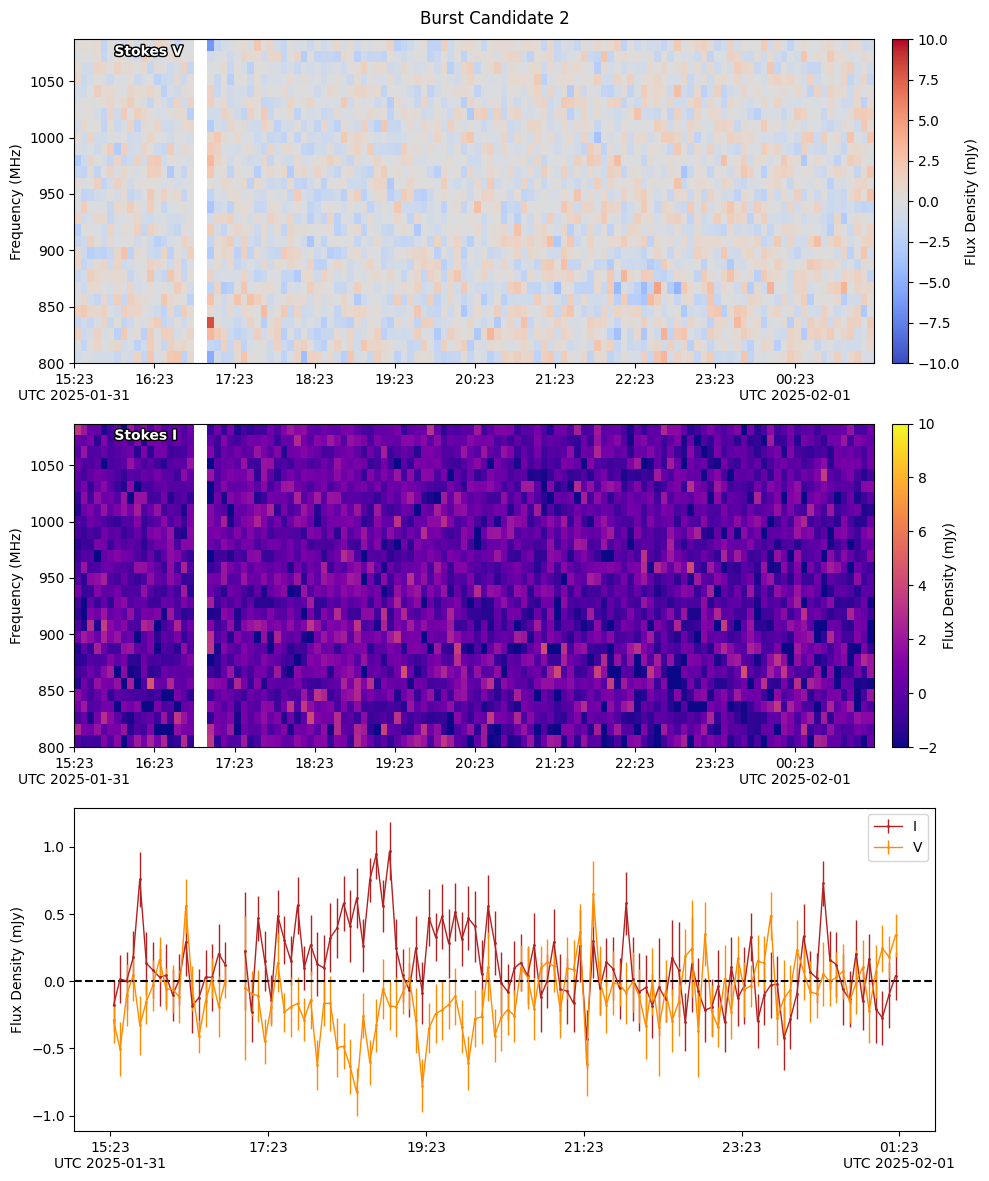

In [9]:
# These are the possibly interesting ones
# tyc_8927_1888_1_emu
# hd82533_emu_0932_51
# hd52118_emu_0649_51
# cd75_652_emu


ds_file = [p for p in ds_files if "cd75_652_emu"  in str(p)][0]

tavg=30
favg = 10
cmax_val = 10

ds = DynamicSpectrum(ds_path=ds_file, tavg=tavg, favg=favg)
lc = LightCurve(ds)

fig, ax = plt.subplots(3, 1, figsize=(10, 12))

# Dynamic spectrum
plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])

# # Dynamic spectrum
# plot_ds(ds, stokes='V', cmax=cmax_val, imag=True, fig=fig, ax=ax[1])

# Dynamic spectrum
plot_ds(ds, stokes='I', cmax=10, imag=False, fig=fig, ax=ax[1])

# Lightcurve
plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[2])
ax[2].axhline(0, c = 'black', ls = '--')

# plt.suptitle(f'{ds_file.stem}')
plt.suptitle('Burst Candidate 2')
plt.tight_layout()
plt.show()

In [13]:
for ds in ds_files:

    temp_ds = DynamicSpectrum(ds_path=ds)  # To get data for averaging
    duration = temp_ds.tmax

    if duration > 4: 
        tavg = 50
    elif duration > 0.75:
        tavg = 20
    else:
        tavg = 5

    favg = 5

    name = ds.stem
    ds = DynamicSpectrum(ds_path=ds, tavg=tavg, favg=favg)
    lc = LightCurve(ds)

    # 2x2 dynamic spectra + lightcurve underneath
    fig, ax = plt.subplots(
        3, 2,
        figsize=(12, 14),
        gridspec_kw={'height_ratios': [1, 1, 0.7]},
        sharex='col'
    )

    # I real
    plot_ds(ds, stokes='I', cmax = 3 * np.nanstd(ds.data['I'].real), imag=False, fig=fig, ax=ax[0, 0])

    # I imaginary
    plot_ds(ds, stokes='I', cmax = 3 * np.nanstd(ds.data['I'].imag), imag=True, fig=fig, ax=ax[0, 1])

    # V real
    plot_ds(ds, stokes='V', cmax = 3 * np.nanstd(ds.data['V'].real), imag=False, fig=fig, ax=ax[1, 0])

    # V imaginary
    plot_ds(ds, stokes='V', cmax = 3 * np.nanstd(ds.data['V'].imag), imag=True, fig=fig, ax=ax[1, 1])

    # Lightcurve spanning both columns
    ax_lc = fig.add_subplot(3, 1, 3)
    plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax_lc)
    ax_lc.axhline(0, c='black', ls='--')

    plt.suptitle(f'{name}')
    plt.tight_layout()
    plt.savefig(f'../rsync_folder/ds_images/{name}_diagnostic_plot.png')
    plt.close(fig)

In [71]:
# # Thesis sidelobe plot
    
# for i, ds_file in enumerate(ds_files):
#     print(i)
#     ds = DynamicSpectrum(ds_path=ds_file, tavg=1, favg=1)
#     cmax_val = 20
    
#     fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
#     plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0])
#     axes[0].set_title('Real component of Stokes I visibility')
    
#     plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1])
#     axes[1].set_title('Imaginary component of Stokes I visibility')
    
    
#     fig.suptitle('RFI Features in dynamic spectra', fontsize=14)
    
#     plt.tight_layout(rect=[0, 0, 1, 0.95])
#     plt.show()

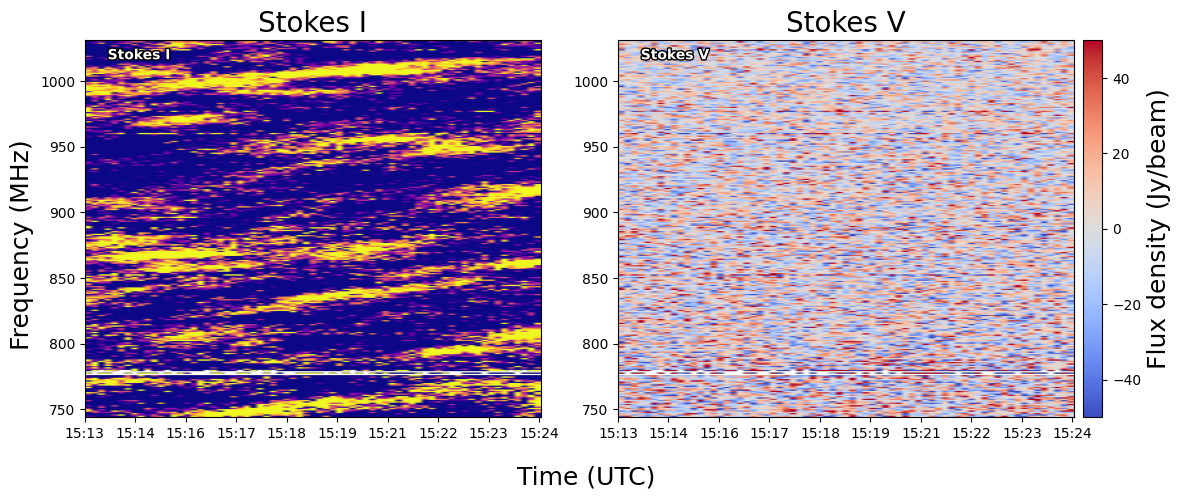

In [69]:
ds = DynamicSpectrum(ds_path=ds_files[17], tavg=1, favg=1)
cmax_val = 50

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_ds(ds, stokes='I', cmax=cmax_val, imag=False, fig=fig, ax=axes[0])
axes[0].set_title('Stokes I', fontsize=20)
axes[0].set_xlabel('')
axes[0].set_ylabel('')
fig.delaxes(fig.axes[-1])

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=axes[1])
axes[1].set_title('Stokes V', fontsize=20)
axes[1].set_xlabel('')
axes[1].set_ylabel('')


# Shared axis labels
fig.supxlabel('Time (UTC)', fontsize=18)
fig.supylabel('Frequency (MHz)', fontsize=18)

# Shared colourbar label
# If plot_ds creates separate colourbars, see note below.
cbar = fig.axes[-1]  # Only appropriate if the last axes is the colourbar
cbar.set_ylabel('Flux density (Jy/beam)', fontsize=18)

plt.tight_layout()
plt.savefig('thesis_figs/model-subtraction.pdf', dpi=300)
plt.show()

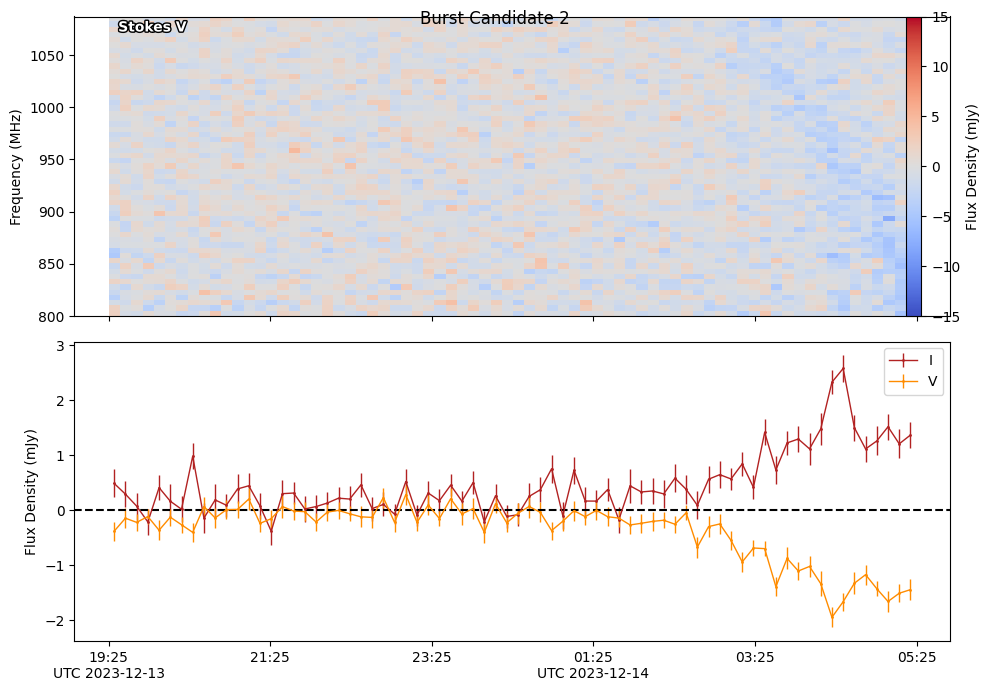

In [30]:
fig, ax = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True
)

plot_ds(ds, stokes='V', cmax=cmax_val, imag=False, fig=fig, ax=ax[0])

plot_lightcurve(lc, stokes='IV', fig=fig, ax=ax[1])
ax[1].axhline(0, c='black', ls='--')

# Force both axes to have the same width and left edge
pos_ds = ax[0].get_position()
pos_lc = ax[1].get_position()

ax[0].set_position([
    pos_lc.x0, pos_ds.y0,
    pos_lc.width, pos_ds.height
])

plt.suptitle('Burst Candidate 2')
plt.show()